Dataset Shape: (5000, 13)
   Flow_Duration  Total_Fwd_Packets  Total_Bwd_Packets  \
0   15050.607155                 15                  7   
1    1013.057114                 11                 10   
2     738.003777                 90                 35   
3    7039.866508                 12                 12   
4     231.409828                 11                  9   

   Total_Length_Fwd_Bytes  Total_Length_Bwd_Bytes  Protocol  Source_Port  \
0                    4626                    3594         1         3457   
1                    1282                    2708         1         2923   
2                    3612                    1463         6        27555   
3                     361                    4447         6        41421   
4                    4193                     529        17        50008   

   Destination_Port  SYN_Flag_Count  RST_Flag_Count  PSH_Flag_Count  \
0              8080               2               1               0   
1                22       

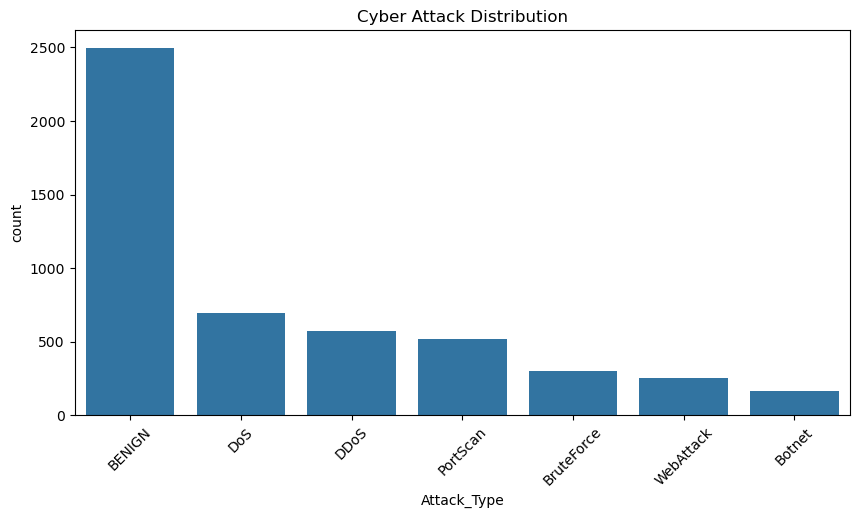


========== MODEL PERFORMANCE ==========
Accuracy : 0.997
Precision: 1.0
Recall   : 0.9940119760479041
F1 Score : 0.996996996996997

Classification Report:
              precision    recall  f1-score   support

      BENIGN       0.99      1.00      1.00       499
      ATTACK       1.00      0.99      1.00       501

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



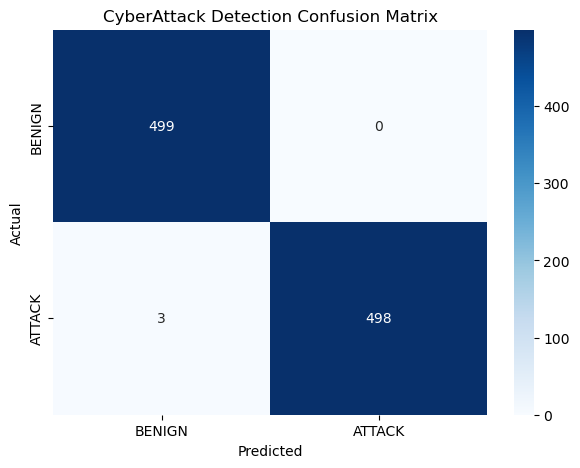


Feature Importance:
                   Feature  Importance
8           SYN_Flag_Count    0.356202
9           RST_Flag_Count    0.223449
2        Total_Bwd_Packets    0.149878
1        Total_Fwd_Packets    0.130237
10          PSH_Flag_Count    0.059896
3   Total_Length_Fwd_Bytes    0.045538
4   Total_Length_Bwd_Bytes    0.025817
0            Flow_Duration    0.005822
6              Source_Port    0.001960
7         Destination_Port    0.000713
5                 Protocol    0.000489


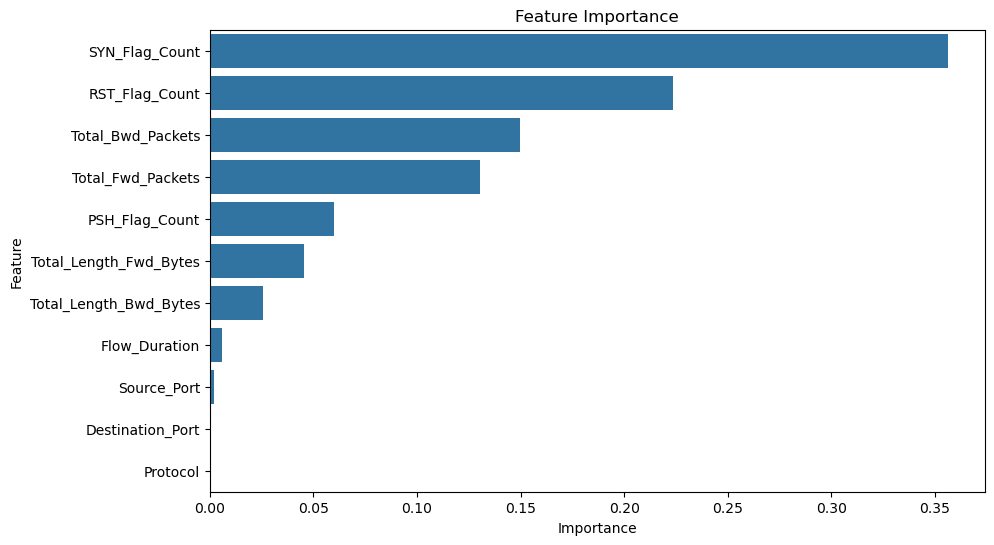


Model and scaler saved successfully!


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# --------------------------------
# 1. LOAD DATA
# --------------------------------

df = pd.read_csv("cyberattack_detection_dataset-2.csv")

print("Dataset Shape:", df.shape)
print(df.head())

# --------------------------------
# 2. CLEAN DATA
# --------------------------------

df = df.drop_duplicates()

print("\nMissing Values:")
print(df.isnull().sum())

# --------------------------------
# 3. ATTACK DISTRIBUTION
# --------------------------------

print("\nAttack Distribution:")
print(df["Attack_Type"].value_counts())

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Attack_Type",
    order=df["Attack_Type"].value_counts().index
)

plt.title("Cyber Attack Distribution")
plt.xticks(rotation=45)
plt.show()

# --------------------------------
# 4. FEATURES AND TARGET
# --------------------------------

X = df.drop(
    ["Attack_Binary", "Attack_Type"],
    axis=1
)

y = df["Attack_Binary"]

# --------------------------------
# 5. TRAIN TEST SPLIT
# --------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# --------------------------------
# 6. SCALING
# --------------------------------

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --------------------------------
# 7. RANDOM FOREST
# --------------------------------

model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train_scaled, y_train)

# --------------------------------
# 8. PREDICTION
# --------------------------------

y_pred = model.predict(X_test_scaled)

# --------------------------------
# 9. EVALUATION
# --------------------------------

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("\n========== MODEL PERFORMANCE ==========")

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["BENIGN", "ATTACK"]
    )
)

# --------------------------------
# 10. CONFUSION MATRIX
# --------------------------------

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["BENIGN", "ATTACK"],
    yticklabels=["BENIGN", "ATTACK"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CyberAttack Detection Confusion Matrix")

plt.show()

# --------------------------------
# 11. FEATURE IMPORTANCE
# --------------------------------

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("\nFeature Importance:")
print(importance)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance")

plt.show()

# --------------------------------
# 12. SAVE MODEL
# --------------------------------

joblib.dump(model, "cyberattack_model.pkl")
joblib.dump(scaler, "cyberattack_scaler.pkl")

print("\nModel and scaler saved successfully!")
